# Day 48: Sales & Service Demand Forecasting System

**Dataset:** the weekly demand history of Day 45 and the forecasts of Day 47 (four service lines,
October 2023 to September 2026, forecast until March 2027)

This notebook is the last of four days in the Sales & Service Demand Forecasting System project.
It shows **why historical trends do not always predict future demand**, builds the **future demand dashboard**, and turns the forecast
into **business planning recommendations**. The same material is in the interactive app `app.py` and in the written `final_report.md`.

## 1. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

DATA_DIR = Path("../datasets/veda_demand")

LINES = ["Internship Programs", "Training Programs", "IT Services", "Digital Services"]
COLORS = {"Internship Programs": "#2a78d6", "Training Programs": "#eb6834", "IT Services": "#1baf7a", "Digital Services": "#eda100"}
METHOD_COLORS = {"Moving average (13 weeks)": "#9aa3b2", "Smoothed seasonal naive with growth": "#008300", "Holt-Winters": "#52514e",
                 "Poisson regression": "#6250d6", "Random forest": "#e87ba4"}
INK, INK_SOFT, GRID, SURFACE = "#0b0b0b", "#52514e", "#dcdad4", "#fcfcfb"
FORECAST_COLOR = "#6250d6"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT,
                     "ytick.color": INK_SOFT, "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.facecolor": SURFACE, "axes.facecolor": SURFACE})


def clean_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)

## 2. Load the History and the Forecasts

In [2]:
WEEK = pd.Timedelta(weeks=1)
weekly = pd.read_csv(DATA_DIR / "cleaned" / "demand_weekly.csv", parse_dates=["week_start"])
holidays = pd.read_csv(DATA_DIR / "reference" / "holiday_calendar.csv", parse_dates=["date"])
future = pd.read_csv(DATA_DIR / "forecasts" / "future_demand_forecast_weekly.csv", parse_dates=["week_start"])
test = pd.read_csv(DATA_DIR / "forecasts" / "model_forecasts_test.csv", parse_dates=["week_start"])
metrics = pd.read_csv(DATA_DIR / "forecasts" / "model_metrics.csv")

history_weeks = pd.DatetimeIndex(sorted(weekly["week_start"].unique()))
future_weeks = pd.DatetimeIndex(sorted(future["week_start"].unique()))
all_weeks = history_weeks.append(future_weeks)

# Revenue per unit of demand of each line over the last 52 weeks (to turn units into rupees)
last_52 = weekly[weekly["week_start"] > history_weeks[-53]].groupby("service_line")[["demand_units", "revenue_inr"]].sum()
revenue_per_unit = (last_52["revenue_inr"] / last_52["demand_units"]).loc[LINES]

# The same 26 weeks one year earlier
year_earlier_weeks = future_weeks - 52 * WEEK
year_earlier = weekly[weekly["week_start"].isin(year_earlier_weeks)].groupby("service_line")[["demand_units", "revenue_inr"]].sum().loc[LINES]

print("History:", len(history_weeks), "weeks | forecast:", len(future_weeks), "weeks (", future_weeks[0].date(), "to", future_weeks[-1].date(), ")")
print("Selected model of Day 47:", future["selected_model"].iloc[0])
print("Revenue per unit of demand, last 52 weeks (INR):")
print(revenue_per_unit.round(0).astype(int).to_dict())

History: 156 weeks | forecast: 26 weeks ( 2026-09-28 to 2027-03-22 )
Selected model of Day 47: Poisson regression
Revenue per unit of demand, last 52 weeks (INR):
{'Internship Programs': 1205, 'Training Programs': 13194, 'IT Services': 89818, 'Digital Services': 11993}


## 3. Why Historical Trends Do Not Always Predict Future Demand

On Day 47 the models were fitted on the weeks until March 23, 2026 and forecast the weeks after it. In the weeks after June 1, 2026
the demand of two lines **changed level** (a lift for Digital Services and a slowdown for IT Services), which is something no model fitted on
the earlier weeks could know. The questions are how large the miss was, and how long it takes to notice it.

**How far the forecast was from what happened after June 1** (the forecast of the Poisson regression, the selected model, without any correction)

In [3]:
after = test[test["week_start"] >= "2026-06-01"]
rows = []
for line in LINES:
    part = after[after["service_line"] == line]
    rows.append({"service_line": line, "forecast_units": part["Poisson regression"].sum(), "actual_units": part["actual"].sum()})
gap = pd.DataFrame(rows).set_index("service_line")
gap["actual_vs_forecast_pct"] = (gap["actual_units"] / gap["forecast_units"] - 1) * 100
gap["missing_units"] = gap["actual_units"] - gap["forecast_units"]
display(gap.round(1))

,forecast_units,actual_units,actual_vs_forecast_pct,missing_units
service_line,,,,
Internship Programs,815.5,874.0,7.2,58.5
Training Programs,762.9,723.0,-5.2,-39.9
IT Services,352.2,284.0,-19.4,-68.2
Digital Services,544.0,646.0,18.8,102.0


**Watching the forecast against reality**

A simple monitor compares what happened with what was forecast. The **8-week ratio** is the demand of the last 8 weeks divided by the forecast for the same 8 weeks, minus 1.
A ratio of 0% means the forecast was right, and a **band of +/-20%** is used to raise a flag. The band is a judgment, not a result: it is set just above the largest
swing of the two lines that did not change (Internship Programs and Training Programs, whose 8-week ratio stayed within 16%), and on real data it should be calibrated on more history.

In [4]:
BAND = 20
monitor_rows = []
for line in LINES:
    part = test[test["service_line"] == line].sort_values("week_start").reset_index(drop=True)
    ratio = (part["actual"].rolling(8).sum() / part["Poisson regression"].rolling(8).sum() - 1) * 100
    cumulative = (part["actual"] - part["Poisson regression"]).cumsum()
    monitor_rows.append(pd.DataFrame({"week_start": part["week_start"], "service_line": line, "actual": part["actual"],
                                      "forecast": part["Poisson regression"], "ratio_8wk_pct": ratio, "cumulative_gap_units": cumulative}))
monitor = pd.concat(monitor_rows, ignore_index=True)
monitor["outside_band"] = monitor["ratio_8wk_pct"].abs() > BAND

CHANGE_START = {"Digital Services": pd.Timestamp("2026-06-01"), "IT Services": pd.Timestamp("2026-07-01")}   # known only because the data is simulated
rows = []
for line in LINES:
    part = monitor[monitor["service_line"] == line]
    first = part.loc[part["outside_band"], "week_start"]
    rows.append({"service_line": line, "largest_8wk_ratio_pct": part["ratio_8wk_pct"].abs().max(),
                 "first_flag": first.iloc[0].date() if len(first) else "none",
                 "weeks_after_the_change_began": round((first.iloc[0] - CHANGE_START[line]).days / 7) if len(first) and line in CHANGE_START else None})
detection = pd.DataFrame(rows).set_index("service_line")
display(detection.round(1))

monitor_out = monitor.copy()
monitor_out["week_start"] = monitor_out["week_start"].dt.strftime("%Y-%m-%d")
monitor_out.round(2).to_csv(DATA_DIR / "forecasts" / "forecast_monitor_weekly.csv", index=False)

,largest_8wk_ratio_pct,first_flag,weeks_after_the_change_began
service_line,,,
Internship Programs,13.0,none,NaN
Training Programs,16.2,none,NaN
IT Services,29.4,2026-07-27,4.0
Digital Services,32.7,2026-09-14,15.0


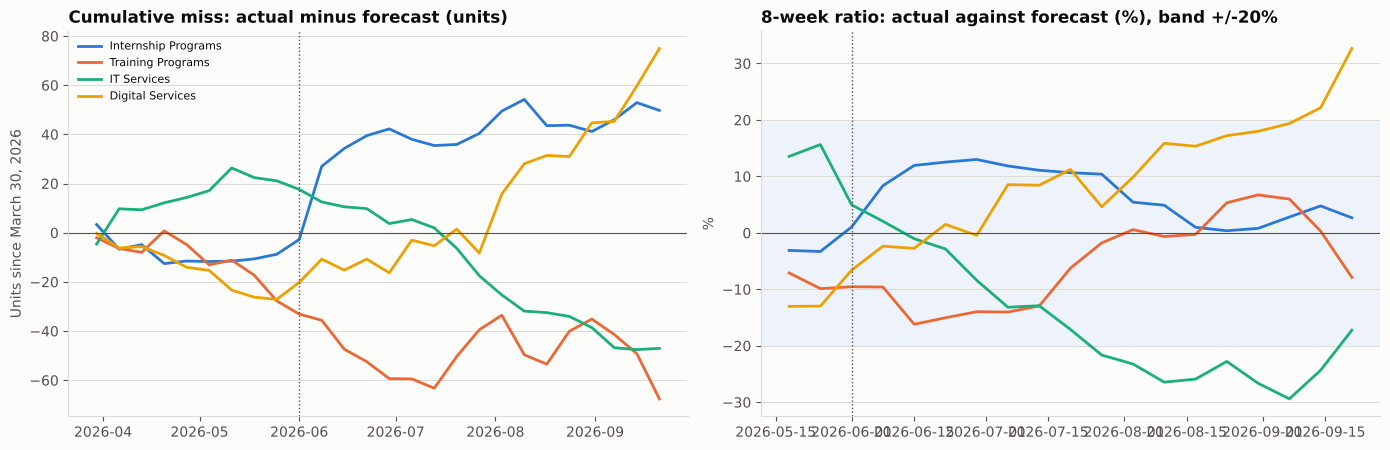

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for line in LINES:
    part = monitor[monitor["service_line"] == line]
    axes[0].plot(part["week_start"], part["cumulative_gap_units"], color=COLORS[line], linewidth=2, label=line)
    axes[1].plot(part["week_start"], part["ratio_8wk_pct"], color=COLORS[line], linewidth=2, label=line)
axes[0].axhline(0, color=INK_SOFT, linewidth=0.8)
axes[0].axvline(pd.Timestamp("2026-06-01"), color=INK_SOFT, linestyle=":", linewidth=1)
axes[0].set_title("Cumulative miss: actual minus forecast (units)")
axes[0].set_ylabel("Units since March 30, 2026")
axes[1].axhspan(-BAND, BAND, color="#eef3fb", zorder=0)
axes[1].axhline(0, color=INK_SOFT, linewidth=0.8)
axes[1].axvline(pd.Timestamp("2026-06-01"), color=INK_SOFT, linestyle=":", linewidth=1)
axes[1].set_title("8-week ratio: actual against forecast (%), band +/-20%")
axes[1].set_ylabel("%")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
for ax in axes:
    clean_axes(ax)
plt.tight_layout()
plt.show()

**Observation:** After June 1 the selected model, which was fitted on the weeks before, was 19% too low for Digital Services (646 units happened against 544 forecast) and 19% too high for IT Services (284 against 352), while Internship Programs (+7%) and Training Programs (-5%) stayed close to their forecasts. The cumulative miss shows it: the curves of Digital Services and IT Services move away from zero week after week, and the other two wander around it. The monitor needed time to notice: the 8-week ratio of the two stable lines never left a band of about 16%, and IT Services crossed the +/-20% band on July 27, 4 weeks after its slowdown began, but Digital Services crossed it only on September 14, 15 weeks after its lift began, because the weekly noise of a single line is large and an 8-week window needs several weeks of evidence. The band was set after seeing these lines, so it is an illustration and not a validated rule. The lesson is that a forecast gives no warning when the pattern changes: someone has to compare it with reality every week.

**Why a trend learned from history can fail**

| Reason | In this project |
|---|---|
| The level changes (a structural break) | Digital Services rose by about a third from June 1, and IT Services slowed from July 1; the models only knew the earlier weeks |
| The pattern is learned from few cycles | Three years hold only three examples of each month, so a seasonal pattern may contain one unusual year |
| The plan changes | Spring 2026 had about half the campaign days of spring 2025, so the methods that copied last year over-forecast |
| Noise hides the change | A week of a single line has about 15% to 20% of random variation, so a real change needs weeks of evidence to be seen |
| The trend does not continue forever | A growth rate fitted on three years cannot say when growth stops |

The practical answer is to treat a forecast as a statement about the history continuing. Put known future drivers (the campaign plan, holidays) into the model, show a range and scenarios and not a single number, compare the forecast with the newest weeks every week, retrain often, and keep the horizon short enough that the pattern is unlikely to change.

## 4. Planning Scenarios: What If the Campaign Plan Changes?

The forecast of Day 47 assumed that campaigns run at the typical load of the last 52 weeks. Because the regression estimates what a campaign day adds,
the same model can answer a planning question: how many units are at stake in the campaign plan? The model is refitted below on all 156 weeks exactly as on Day 47
(the same trend, the same yearly waves, the same level correction), and the forecast is repeated with three campaign plans.

In [6]:
def season_terms(frame, K=3):
    terms = {}
    for k in range(1, K + 1):
        terms[f"sin{k}"] = np.sin(2 * np.pi * k * frame["doy"])
        terms[f"cos{k}"] = np.cos(2 * np.pi * k * frame["doy"])
    return pd.DataFrame(terms, index=frame.index)


def design(frame):
    return sm.add_constant(pd.concat([frame[["t", "camp", "hol"]], season_terms(frame)], axis=1), has_constant="add").to_numpy()


def make_frame(line):
    part = weekly[weekly["service_line"] == line].set_index("week_start").sort_index()
    ahead = future[future["service_line"] == line].set_index("week_start").loc[future_weeks]
    frame = pd.DataFrame(index=all_weeks)
    frame["y"] = part["demand_units"].astype(float).reindex(all_weeks)
    frame["camp"] = part["campaign_days"].astype(float).reindex(all_weeks)
    frame.loc[future_weeks, "camp"] = ahead["campaign_days_assumed"].to_numpy()
    frame["hol"] = [((holidays["date"] >= s) & (holidays["date"] < s + WEEK)).sum() for s in history_weeks] + ahead["holidays_in_week"].tolist()
    frame["t"] = np.arange(len(all_weeks)) / 52.0
    frame["doy"] = (all_weeks + pd.Timedelta(days=3)).dayofyear / 365.25
    return frame


N = len(history_weeks)
PLANS = {"No campaigns": 0.0, "Typical campaign load": 1.0, "Campaigns +50%": 1.5}
rows, models = [], {}
for line in LINES:
    frame = make_frame(line)
    model = sm.GLM(frame["y"].iloc[:N].to_numpy(), design(frame.iloc[:N]), family=sm.families.Poisson()).fit()
    fitted = model.predict(design(frame.iloc[:N]))
    level = frame["y"].iloc[N - 13:N].sum() / fitted[-13:].sum()          # the level correction of Day 47
    typical = frame["camp"].iloc[N:].to_numpy()
    for plan, factor in PLANS.items():
        scenario = frame.iloc[N:].copy()
        scenario["camp"] = np.minimum(typical * factor, 7.0)
        units = model.predict(design(scenario)) * level
        rows.append(pd.DataFrame({"week_start": future_weeks, "service_line": line, "plan": plan, "campaign_days": scenario["camp"].to_numpy(), "forecast_units": units}))
    models[line] = model
scenarios = pd.concat(rows, ignore_index=True)

# The typical plan must reproduce the forecast of Day 47
typical_plan = scenarios[scenarios["plan"] == "Typical campaign load"].merge(future[["week_start", "service_line", "forecast"]], on=["week_start", "service_line"])
print("Typical plan = forecast of Day 47 (largest difference in units):", round(float((typical_plan["forecast_units"] - typical_plan["forecast"]).abs().max()), 3))

by_plan = scenarios.pivot_table(index="service_line", columns="plan", values="forecast_units", aggfunc="sum").loc[LINES][list(PLANS)]
by_plan["campaign_effect_pct"] = (by_plan["Campaigns +50%"] / by_plan["No campaigns"] - 1) * 100
by_plan["units_between_none_and_typical"] = by_plan["Typical campaign load"] - by_plan["No campaigns"]
by_plan["revenue_between_none_and_typical_INR_M"] = by_plan["units_between_none_and_typical"] * revenue_per_unit / 1e6
by_plan["revenue_plus_50_vs_typical_INR_M"] = (by_plan["Campaigns +50%"] - by_plan["Typical campaign load"]) * revenue_per_unit / 1e6
total_row = by_plan.sum()
total_row["campaign_effect_pct"] = (by_plan["Campaigns +50%"].sum() / by_plan["No campaigns"].sum() - 1) * 100
by_plan.loc["All lines"] = total_row
print("Units forecast in the 26 weeks under three campaign plans (the campaign days of the typical plan are in the table below):")
display(by_plan.round(1))
print("Typical campaign days per week assumed:", {line: round(float(make_frame(line)["camp"].iloc[-1]), 2) for line in LINES})

scenarios_out = scenarios.copy()
scenarios_out["week_start"] = scenarios_out["week_start"].dt.strftime("%Y-%m-%d")
scenarios_out.round(2).to_csv(DATA_DIR / "forecasts" / "campaign_scenarios_weekly.csv", index=False)

Typical plan = forecast of Day 47 (largest difference in units): 0.017
Units forecast in the 26 weeks under three campaign plans (the campaign days of the typical plan are in the table below):


plan,No campaigns,Typical campaign load,Campaigns +50%,campaign_effect_pct,units_between_none_and_typical,revenue_between_none_and_typical_INR_M,revenue_plus_50_vs_typical_INR_M
service_line,,,,,,,
Internship Programs,1306.1,1409.9,1464.8,12.1,103.7,0.1,0.1
Training Programs,903.2,978.6,1018.6,12.8,75.4,1.0,0.5
IT Services,450.0,465.5,473.5,5.2,15.6,1.4,0.7
Digital Services,716.0,778.4,811.6,13.3,62.4,0.7,0.4
All lines,3375.3,3632.4,3768.5,11.6,257.1,3.3,1.7


Typical campaign days per week assumed: {'Internship Programs': 1.87, 'Training Programs': 2.25, 'IT Services': 1.6, 'Digital Services': 1.73}


**Observation:** The campaign plan moves the forecast noticeably. The 26-week total is 3,375 units without campaigns, 3,632 with the typical load (257 units or 7.6% more), and 3,769 with 50% more campaign days (136 more units). The typical campaigns add most units in Internship Programs (104) and Training Programs (75), then Digital Services (62), and very few in IT Services (16). In rupees the order reverses, because one IT unit is worth about INR 89,818 and one Internship unit about INR 1,205: the typical campaigns are worth about INR 3.3 million in all, of which IT Services give INR 1.4 million and Training Programs INR 1.0 million, but Internship Programs only INR 0.1 million, and 50% more campaign days would add about INR 1.7 million. These are scenarios and not predictions: the model assumes that every extra campaign day adds the same percentage (real campaigns usually have diminishing returns), the costs of the campaigns are not known, and the IT effect is the least certain. The typical plan reproduces the forecast of Day 47 to within 0.02 units, which is the rounding of the saved file.

## 5. Planning View: Revenue and Peak Weeks

Units are not rupees: IT Services have the fewest units and the largest revenue per unit, so the same percentage change means very different money in each line.
The revenue below is the forecast units times the revenue per unit of the last 52 weeks, and it is compared with the same 26 weeks one year earlier.

In [7]:
units_forecast = future.groupby("service_line")[["forecast", "model_forecast", "range_low", "range_high"]].sum().loc[LINES]
plan = pd.DataFrame({
    "units_year_earlier": year_earlier["demand_units"],
    "units_forecast": units_forecast["forecast"],
    "units_change_pct": (units_forecast["forecast"] / year_earlier["demand_units"] - 1) * 100,
    "revenue_year_earlier_INR_M": year_earlier["revenue_inr"] / 1e6,
    "revenue_forecast_INR_M": units_forecast["forecast"] * revenue_per_unit / 1e6,
})
plan["revenue_change_INR_M"] = plan["revenue_forecast_INR_M"] - plan["revenue_year_earlier_INR_M"]
plan["share_of_forecast_revenue_pct"] = plan["revenue_forecast_INR_M"] / plan["revenue_forecast_INR_M"].sum() * 100
plan.loc["All lines"] = [plan["units_year_earlier"].sum(), plan["units_forecast"].sum(), (plan["units_forecast"].sum() / plan["units_year_earlier"].sum() - 1) * 100,
                         plan["revenue_year_earlier_INR_M"].sum(), plan["revenue_forecast_INR_M"].sum(),
                         plan["revenue_forecast_INR_M"].sum() - plan["revenue_year_earlier_INR_M"].sum(), 100.0]
display(plan.round(1))

,units_year_earlier,units_forecast,units_change_pct,revenue_year_earlier_INR_M,revenue_forecast_INR_M,revenue_change_INR_M,share_of_forecast_revenue_pct
service_line,,,,,,,
Internship Programs,1338.0,1409.6,5.3,1.6,1.7,0.1,2.6
Training Programs,879.0,978.6,11.3,11.5,12.9,1.4,19.6
IT Services,498.0,465.5,-6.5,44.7,41.8,-2.9,63.6
Digital Services,538.0,778.4,44.7,6.4,9.3,2.9,14.2
All lines,3253.0,3632.1,11.7,64.2,65.8,1.5,100.0


In [8]:
# Plan month = the month of the Thursday of the week, so every one of the 26 weeks belongs to exactly one month
future["plan_month"] = (future["week_start"] + pd.Timedelta(days=3)).dt.to_period("M").astype(str)
monthly = future.pivot_table(index="plan_month", columns="service_line", values="forecast", aggfunc="sum")[LINES]
monthly["All lines"] = monthly.sum(axis=1)
monthly["weeks"] = future[future["service_line"] == LINES[0]].groupby("plan_month").size()
print("Forecast units by plan month:")
display(monthly.round(0).astype(int))
per_week = monthly[LINES + ["All lines"]].div(monthly["weeks"], axis=0)
print("The same, in units per week (months have 4 or 5 weeks, so this is the fair way to compare them):")
display(per_week.round(1))
average_week_all = future.groupby("week_start")["forecast"].sum().mean()

peaks = (future.sort_values("forecast", ascending=False).groupby("service_line").head(3).sort_values(["service_line", "forecast"], ascending=[True, False])
         [["service_line", "week_start", "forecast", "range_high"]])
peaks["week_start"] = peaks["week_start"].dt.date
average_week = future.groupby("service_line")["forecast"].mean()
peaks["times_the_average_week"] = peaks["forecast"] / peaks["service_line"].map(average_week)
print("The three busiest forecast weeks of each line (range_high = the demand to plan for if the week is a busy one):")
display(peaks.set_index("service_line").loc[LINES].round(1))

Forecast units by plan month:


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines,weeks
plan_month,,,,,,
2026-10,222,185,97,165,669,5
2026-11,202,151,75,139,567,4
2026-12,262,163,62,142,629,5
2027-01,268,167,59,103,596,4
2027-02,253,169,79,105,607,4
2027-03,202,144,93,124,562,4


The same, in units per week (months have 4 or 5 weeks, so this is the fair way to compare them):


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines
plan_month,,,,,
2026-10,44.5,37.0,19.4,33.0,133.8
2026-11,50.5,37.9,18.7,34.8,141.8
2026-12,52.4,32.5,12.5,28.5,125.9
2027-01,67.1,41.7,14.6,25.7,149.1
2027-02,63.4,42.3,19.9,26.3,151.8
2027-03,50.4,35.9,23.3,31.0,140.6


The three busiest forecast weeks of each line (range_high = the demand to plan for if the week is a busy one):


,week_start,forecast,range_high,times_the_average_week
service_line,,,,
Internship Programs,2027-01-18,67.8,88.5,1.3
Internship Programs,2027-01-25,67.7,88.4,1.2
Internship Programs,2027-01-11,67.1,87.6,1.2
Training Programs,2027-02-01,42.8,54.8,1.1
Training Programs,2027-02-08,42.7,54.7,1.1
Training Programs,2027-01-25,42.6,54.5,1.1
IT Services,2027-03-15,25.5,32.8,1.4
IT Services,2027-03-08,24.9,32.1,1.4
IT Services,2027-03-01,23.8,30.7,1.3


**Observation:** Units and rupees tell different stories. Demand is forecast 11.7% above the same weeks a year earlier (3,632 units), but the revenue is only 2.4% higher (INR 65.8 million against INR 64.2 million), because the growth is in the cheap lines and the fall is in the expensive one: Digital Services add INR 2.9 million and Training Programs INR 1.4 million, while IT Services lose INR 2.9 million, and IT Services are still 64% of the revenue. Per week, all lines together are busiest in January and February (149 and 152 units, with Internship Programs at 63 to 67) and quietest in December (126), which is mostly the holidays. The busiest forecast weeks are January 18 for Internship Programs (68 units, up to 89 in the range), February 1 for Training Programs (43 units), March 15 for IT Services (26 units), and November 16 for Digital Services (35 units); the upper end of the range is the figure to plan capacity for in those weeks.

## 6. Business Planning Recommendations

Each recommendation has the evidence, a concrete action, and an impact that is labeled as a scenario with its assumptions.
The evidence is calculated from the tables above, so every number can be traced back to the data.
All the data is simulated, so these are examples of the workflow and not advice for the real company.

In [9]:
inr = lambda value: f"INR {value:,.1f} million"
it, dg, ip, tp = (plan.loc[name] for name in ["IT Services", "Digital Services", "Internship Programs", "Training Programs"])
rr = revenue_per_unit
peak_ip = peaks[peaks["service_line"] == "Internship Programs"].iloc[0]
peak_dg = peaks[peaks["service_line"] == "Digital Services"].iloc[0]
dec_change = (per_week.loc["2026-12", "All lines"] / average_week_all - 1) * 100
effect = {line: by_plan.loc[line, "campaign_effect_pct"] for line in LINES}
low_line, high_line = min(effect, key=effect.get), max(effect, key=effect.get)
coverage_all = test["inside_range"].mean() * 100
gap_dg, gap_it = gap.loc["Digital Services"], gap.loc["IT Services"]
flag_it, flag_dg = detection.loc["IT Services"], detection.loc["Digital Services"]
total_plan = plan.loc["All lines"]

recommendations = pd.DataFrame([
    {"priority": "High", "segment_or_area": "IT Services (revenue risk)",
     "evidence": (f"IT Services are {it['share_of_forecast_revenue_pct']:.0f}% of the forecast revenue ({inr(it['revenue_forecast_INR_M'])} over the next 26 weeks) and its forecast changes by {it['units_change_pct']:+.0f}% in units against the same weeks a year earlier "
                  f"({it['units_forecast']:.0f} against {it['units_year_earlier']:.0f}). After June 1 the demand was {abs(gap_it['actual_vs_forecast_pct']):.0f}% below the forecast of the model that did not know about the slowdown, and the weekly ranges "
                  f"add up to {units_forecast.loc['IT Services', 'range_low']:.0f} to {units_forecast.loc['IT Services', 'range_high']:.0f} units."),
     "recommendation": "Treat IT Services as the largest revenue risk: find out why demand slowed (pipeline, pricing, renewals), review the forecast every week against the 8-week ratio, and do not cut IT capacity until the ratio stays below -20% for a longer period.",
     "estimated_impact": (f"Scenario: every 10% of IT units is about {inr(it['units_forecast'] * 0.1 * rr['IT Services'] / 1e6)} over 26 weeks at INR {rr['IT Services']:,.0f} per unit. "
                          f"If IT units ended 10% below even this forecast, that revenue would be lost.")},
    {"priority": "High", "segment_or_area": "Digital Services (capacity)",
     "evidence": (f"Digital Services are forecast at {dg['units_forecast']:.0f} units, {dg['units_change_pct']:+.0f}% against the same weeks a year earlier ({dg['units_year_earlier']:.0f}). "
                  f"After June 1 demand was {gap_dg['actual_vs_forecast_pct']:.0f}% above the forecast of the model that did not know about the lift, and the busiest forecast week is {peak_dg['forecast']:.0f} units "
                  f"(up to {peak_dg['range_high']:.0f} in the range)."),
     "recommendation": "Plan delivery capacity for Digital Services from the corrected forecast and keep a reserve for the upper end of the range in the busiest weeks; re-check the level every month, since the lift can fade or continue.",
     "estimated_impact": (f"Scenario: planning from last year's {dg['units_year_earlier']:.0f} units instead of the forecast {dg['units_forecast']:.0f} would leave {dg['units_forecast'] - dg['units_year_earlier']:.0f} units without capacity, "
                          f"about {inr((dg['units_forecast'] - dg['units_year_earlier']) * rr['Digital Services'] / 1e6)} of revenue at INR {rr['Digital Services']:,.0f} per unit.")},
    {"priority": "High", "segment_or_area": "Forecast monitoring",
     "evidence": (f"The 8-week actual-against-forecast ratio left the +/-{BAND}% band for IT Services at {flag_it['first_flag']} ({flag_it['weeks_after_the_change_began']:.0f} weeks after its slowdown began) and for Digital Services at "
                  f"{flag_dg['first_flag']} ({flag_dg['weeks_after_the_change_began']:.0f} weeks after its lift began), and never for Internship Programs or Training Programs. The weekly noise and the 8-week window are the reason for the delay."),
     "recommendation": "Run the 8-week ratio every week for every line, retrain the models every month with the newest weeks, and review any line outside the band; keep the forecast with and without the level correction so that the effect of the change can be seen.",
     "estimated_impact": "Process improvement, not a forecast of money: a monitor that flags a change in about one to four months is better than finding it at the end of the year, but it cannot flag it at once."},
    {"priority": "High", "segment_or_area": "Campaign plan",
     "evidence": (f"The forecast depends on the campaign plan: without campaigns the 26-week total would be {by_plan.loc['All lines', 'No campaigns']:.0f} units, with the typical load {by_plan.loc['All lines', 'Typical campaign load']:.0f}, "
                  f"and with 50% more campaign days {by_plan.loc['All lines', 'Campaigns +50%']:.0f}. The lift of +50% campaign days over no campaigns differs by line, from +{effect[low_line]:.0f}% in {low_line} to +{effect[high_line]:.0f}% in {high_line}. "
                  f"In revenue, the typical campaigns are worth {inr(by_plan.loc['IT Services', 'revenue_between_none_and_typical_INR_M'])} in IT Services against {inr(by_plan.loc['Internship Programs', 'revenue_between_none_and_typical_INR_M'])} in Internship Programs, "
                  f"although the campaign effect of IT Services is the least certain (an interval of +2% to +31% for a full campaign week on Day 46)."),
     "recommendation": "Share the campaign calendar with the forecast owners before every forecast run, and put the extra campaign days where a campaign adds the most revenue per day, not where it adds the most units.",
     "estimated_impact": (f"Scenario: 50% more campaign days than typical add {by_plan.loc['All lines', 'Campaigns +50%'] - by_plan.loc['All lines', 'Typical campaign load']:.0f} units, which is about "
                          f"{inr(by_plan.loc['All lines', 'revenue_plus_50_vs_typical_INR_M'])} of revenue at the revenue per unit of each line, before the cost of the campaigns.")},
    {"priority": "Medium", "segment_or_area": "Internship Programs (seasonal capacity)",
     "evidence": (f"Internship Programs peak at {peak_ip['forecast']:.0f} units a week in January ({peak_ip['times_the_average_week']:.1f} times the average week of the forecast), and January and February are the busiest months "
                  f"({per_week.loc['2027-01', 'Internship Programs']:.0f} and {per_week.loc['2027-02', 'Internship Programs']:.0f} units per week, against {per_week.loc['2026-10', 'Internship Programs']:.0f} in October). They are {ip['units_forecast'] / plan.loc['All lines', 'units_forecast'] * 100:.0f}% of the forecast units but only {ip['share_of_forecast_revenue_pct']:.1f}% of the revenue."),
     "recommendation": "Plan mentors, seats, and intake dates for the peak weeks and keep the cost per intern low outside them; revenue is small, so the peak is a capacity question and not a growth bet.",
     "estimated_impact": "Capacity planning scenario: sizing for the average week would leave the peak weeks about "
                         f"{(peak_ip['times_the_average_week'] - 1) * 100:.0f}% short of the demand; sizing for the peak would leave the average week with idle capacity."},
    {"priority": "Medium", "segment_or_area": "Training Programs (calendar)",
     "evidence": (f"Training Programs are forecast at {tp['units_forecast']:.0f} units ({tp['units_change_pct']:+.0f}% against the same weeks a year earlier), December has {dec_change:+.0f}% units per week against the average week of all lines "
                  f"(the holidays), and the yearly peak of Training Programs is in July, outside the forecast period."),
     "recommendation": "Use the quiet weeks of the holiday period for course preparation and for the campaign days that the plan allows, and prepare the July peak early.",
     "estimated_impact": "Not quantified: the gain is a smoother workload, and the simulated data has no cost of preparing a course to turn it into money."},
    {"priority": "Medium", "segment_or_area": "Data and model limits",
     "evidence": (f"The selected regression has a WAPE of {metrics[(metrics['method'] == 'Poisson regression') & (metrics['service_line'] == 'All lines')]['WAPE_pct'].iloc[0]:.1f}% on the weekly total but 10% to 23% by line on the test weeks, "
                  f"its 80% ranges contained {coverage_all:.1f}% of the test line-weeks, and it has seen only three years of simulated data."),
     "recommendation": "Use the forecast for planning about 26 weeks ahead and not beyond, read it with its ranges, and replace the simulated history with the real inquiry history as soon as it is available.",
     "estimated_impact": "Risk control: it avoids planning on a point forecast that the data cannot support."},
])
recommendations.to_csv("business_planning_recommendations.csv", index=False)
print("Saved business_planning_recommendations.csv with", len(recommendations), "recommendations")
recommendations[["priority", "segment_or_area", "evidence", "recommendation", "estimated_impact"]]

Saved business_planning_recommendations.csv with 7 recommendations


,priority,segment_or_area,evidence,recommendation,estimated_impact
0,High,IT Services (revenue risk),IT Services are 64% of the forecast revenue (INR 41.8 million over the next 26 weeks) and its forecast changes by -7...,"Treat IT Services as the largest revenue risk: find out why demand slowed (pipeline, pricing, renewals), review the ...","Scenario: every 10% of IT units is about INR 4.2 million over 26 weeks at INR 89,818 per unit. If IT units ended 10%..."
1,High,Digital Services (capacity),"Digital Services are forecast at 778 units, +45% against the same weeks a year earlier (538). After June 1 demand wa...",Plan delivery capacity for Digital Services from the corrected forecast and keep a reserve for the upper end of the ...,"Scenario: planning from last year's 538 units instead of the forecast 778 would leave 240 units without capacity, ab..."
2,High,Forecast monitoring,The 8-week actual-against-forecast ratio left the +/-20% band for IT Services at 2026-07-27 (4 weeks after its slowd...,"Run the 8-week ratio every week for every line, retrain the models every month with the newest weeks, and review any...","Process improvement, not a forecast of money: a monitor that flags a change in about one to four months is better th..."
3,High,Campaign plan,"The forecast depends on the campaign plan: without campaigns the 26-week total would be 3375 units, with the typical...","Share the campaign calendar with the forecast owners before every forecast run, and put the extra campaign days wher...","Scenario: 50% more campaign days than typical add 136 units, which is about INR 1.7 million of revenue at the revenu..."
4,Medium,Internship Programs (seasonal capacity),"Internship Programs peak at 68 units a week in January (1.3 times the average week of the forecast), and January and...","Plan mentors, seats, and intake dates for the peak weeks and keep the cost per intern low outside them; revenue is s...",Capacity planning scenario: sizing for the average week would leave the peak weeks about 25% short of the demand; si...
5,Medium,Training Programs (calendar),"Training Programs are forecast at 979 units (+11% against the same weeks a year earlier), December has -10% units pe...","Use the quiet weeks of the holiday period for course preparation and for the campaign days that the plan allows, and...","Not quantified: the gain is a smoother workload, and the simulated data has no cost of preparing a course to turn it..."
6,Medium,Data and model limits,"The selected regression has a WAPE of 7.2% on the weekly total but 10% to 23% by line on the test weeks, its 80% ran...","Use the forecast for planning about 26 weeks ahead and not beyond, read it with its ranges, and replace the simulate...",Risk control: it avoids planning on a point forecast that the data cannot support.


**Observation:** Seven recommendations came out of the forecast, four of them of high priority: protect the IT Services revenue, which is 64% of the money but has the weakest outlook (-7% in units); prepare capacity for Digital Services, whose demand is forecast 45% above a year earlier; monitor the forecast against reality every week, since changes took 4 and 15 weeks to appear; and share the campaign calendar with the forecast, because the plan alone moves the 26-week total by several hundred units. The medium ones plan the seasonal peak of Internship Programs, use the quiet December weeks for Training Programs, and keep the limits of the data in view. Each impact is a scenario with its assumptions, not a promise.

## 7. Future Demand Dashboard (Static)

The dashboard collects what a planner needs on one page: the forecast of the next 26 weeks with its range, the change against the same weeks a year earlier,
the plan by month, how accurate the methods were on the test weeks, what the campaign plan is worth, and the monitor that shows whether the forecast is still on track.
It is saved as `future_demand_dashboard.png`.

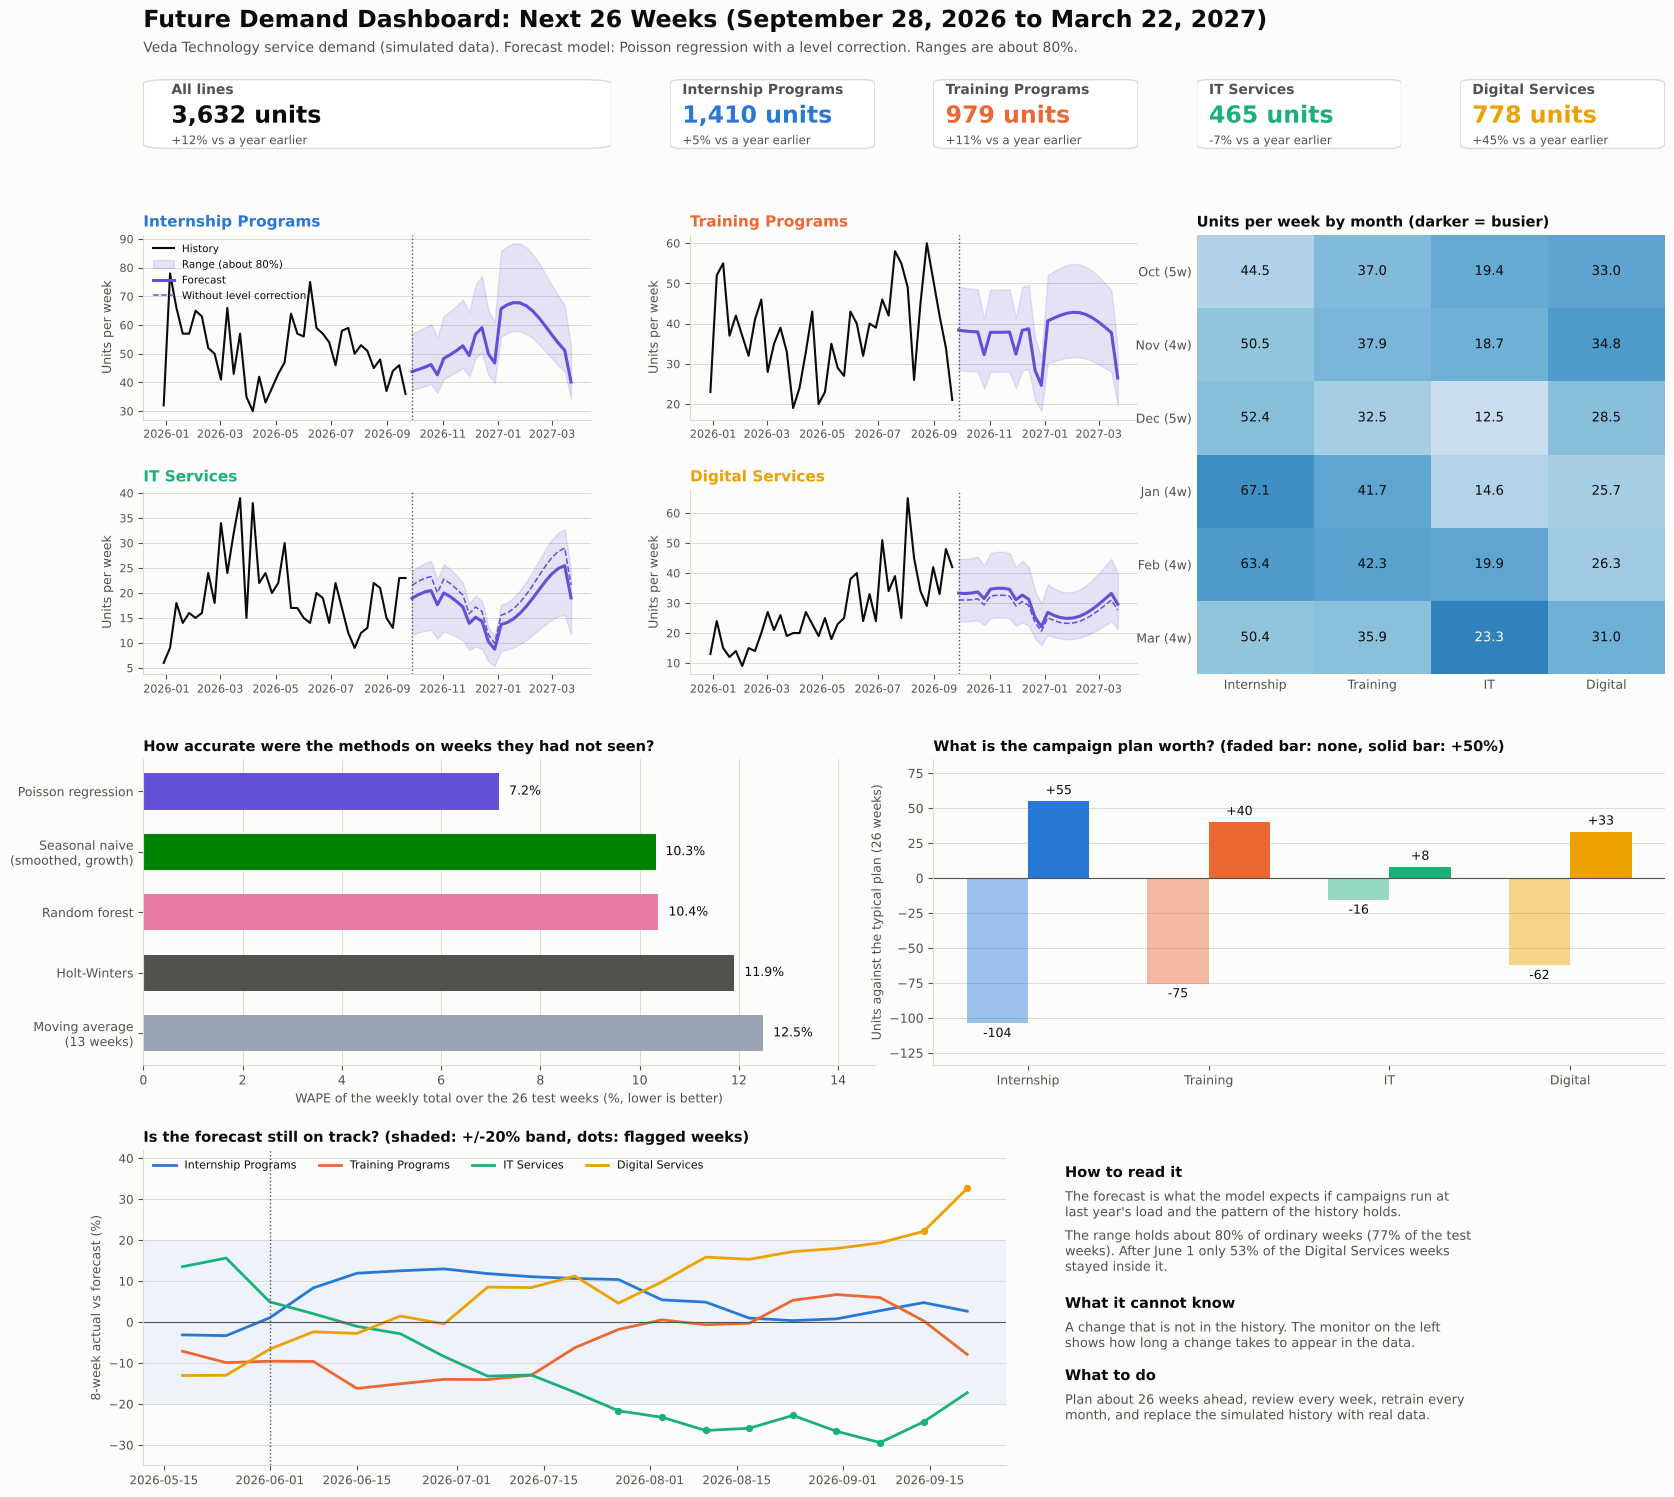

In [10]:
fig = plt.figure(figsize=(17, 15.5))
outer = fig.add_gridspec(4, 12, height_ratios=[0.75, 4.6, 3.2, 3.3], hspace=0.3, wspace=0.8, left=0.09, right=0.985, top=0.935, bottom=0.04)
fig.text(0.09, 0.968, "Future Demand Dashboard: Next 26 Weeks (September 28, 2026 to March 22, 2027)", fontsize=17, fontweight="bold", ha="left")
fig.text(0.09, 0.952, "Veda Technology service demand (simulated data). Forecast model: Poisson regression with a level correction. Ranges are about 80%.", fontsize=10, color=INK_SOFT, ha="left")

# ---- Tiles ----
tile_specs = [("All lines", slice(0, 4))] + [(line, slice(4 + 2 * i, 6 + 2 * i)) for i, line in enumerate(LINES)]
for name, cols in tile_specs:
    ax = fig.add_subplot(outer[0, cols])
    ax.set_axis_off()
    ax.add_patch(FancyBboxPatch((0.0, 0.02), 1.0, 0.96, boxstyle="round,pad=0,rounding_size=0.06", transform=ax.transAxes, facecolor="white", edgecolor=GRID, linewidth=1))
    row = plan.loc[name]
    color = INK if name == "All lines" else COLORS[name]
    ax.text(0.06, 0.78, name, transform=ax.transAxes, fontsize=10, color=INK_SOFT, fontweight="bold")
    ax.text(0.06, 0.38, f"{row['units_forecast']:,.0f} units", transform=ax.transAxes, fontsize=17, fontweight="bold", color=color)
    ax.text(0.06, 0.08, f"{row['units_change_pct']:+.0f}% vs a year earlier", transform=ax.transAxes, fontsize=8.5, color=INK_SOFT)

# ---- Forecast small multiples ----
inner = outer[1, 0:8].subgridspec(2, 2, hspace=0.38, wspace=0.22)
for i, line in enumerate(LINES):
    ax = fig.add_subplot(inner[i // 2, i % 2])
    part = future[future["service_line"] == line].set_index("week_start")
    history = weekly[weekly["service_line"] == line].set_index("week_start")["demand_units"].iloc[-39:]
    ax.plot(history.index, history, color=INK, linewidth=1.5, label="History")
    ax.fill_between(part.index, part["range_low"], part["range_high"], color=FORECAST_COLOR, alpha=0.15, label="Range (about 80%)")
    ax.plot(part.index, part["forecast"], color=FORECAST_COLOR, linewidth=2.2, label="Forecast")
    ax.plot(part.index, part["model_forecast"], color=FORECAST_COLOR, linewidth=1.1, linestyle="--", label="Without level correction")
    ax.axvline(future_weeks[0], color=INK_SOFT, linestyle=":", linewidth=1)
    ax.set_title(line, fontsize=11, color=COLORS[line])
    ax.set_ylabel("Units per week", fontsize=9)
    ax.tick_params(labelsize=8)
    clean_axes(ax)
    if i == 0:
        ax.legend(loc="upper left", frameon=False, fontsize=7.5)

# ---- Monthly plan heatmap (share of the line's average month) ----
ax = fig.add_subplot(outer[1, 8:12])
grid = per_week[LINES]
relative = grid / grid.mean()
ax.imshow(relative.to_numpy(), cmap="Blues", vmin=0.4, vmax=1.7, aspect="auto")
ax.set_xticks(range(4))
ax.set_xticklabels(["Internship", "Training", "IT", "Digital"], fontsize=9)
ax.set_yticks(range(len(grid)))
ax.set_yticklabels([f"{pd.Period(m).strftime('%b')} ({monthly.loc[m, 'weeks']}w)" for m in grid.index], fontsize=9)
for r in range(grid.shape[0]):
    for c in range(grid.shape[1]):
        ax.text(c, r, f"{grid.iloc[r, c]:,.1f}", ha="center", va="center", fontsize=9.5, color="white" if relative.iloc[r, c] > 1.25 else INK)
ax.set_title("Units per week by month (darker = busier)", fontsize=10.5)
for side in ax.spines.values():
    side.set_visible(False)
ax.tick_params(length=0)

# ---- Accuracy ----
ax = fig.add_subplot(outer[2, 0:6])
total_wape = metrics[metrics["service_line"] == "All lines"].set_index("method")["WAPE_pct"].sort_values(ascending=False)
short_names = {"Smoothed seasonal naive with growth": "Seasonal naive\n(smoothed, growth)", "Moving average (13 weeks)": "Moving average\n(13 weeks)"}
bars = ax.barh([short_names.get(m, m) for m in total_wape.index], total_wape.values, color=[METHOD_COLORS[m] for m in total_wape.index], height=0.6)
for position, value in enumerate(total_wape.values):
    ax.text(value + 0.2, position, f"{value:.1f}%", va="center", fontsize=9)
ax.set_xlabel("WAPE of the weekly total over the 26 test weeks (%, lower is better)", fontsize=9)
ax.set_title("How accurate were the methods on weeks they had not seen?", fontsize=10.5)
ax.set_xlim(0, total_wape.max() * 1.18)
ax.tick_params(labelsize=9)
clean_axes(ax, "x")

# ---- Campaign scenarios ----
ax = fig.add_subplot(outer[2, 6:12])
width = 0.34
x = np.arange(len(LINES))
none_gap = (by_plan.loc[LINES, "No campaigns"] - by_plan.loc[LINES, "Typical campaign load"]).to_numpy()
plus_gap = (by_plan.loc[LINES, "Campaigns +50%"] - by_plan.loc[LINES, "Typical campaign load"]).to_numpy()
ax.bar(x - width / 2, none_gap, width, color=[COLORS[l] for l in LINES], alpha=0.45, label="No campaigns")
ax.bar(x + width / 2, plus_gap, width, color=[COLORS[l] for l in LINES], label="Campaigns +50%")
for xi, v in zip(x - width / 2, none_gap):
    ax.text(xi, v - 3, f"{v:.0f}", ha="center", va="top", fontsize=9)
for xi, v in zip(x + width / 2, plus_gap):
    ax.text(xi, v + 3, f"+{v:.0f}", ha="center", va="bottom", fontsize=9)
ax.axhline(0, color=INK_SOFT, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(["Internship", "Training", "IT", "Digital"], fontsize=9)
ax.set_ylabel("Units against the typical plan (26 weeks)", fontsize=9)
ax.set_ylim(none_gap.min() - 30, plus_gap.max() + 30)
ax.set_title("What is the campaign plan worth? (faded bar: none, solid bar: +50%)", fontsize=10.5)
ax.tick_params(labelsize=9)
clean_axes(ax)

# ---- Monitor ----
ax = fig.add_subplot(outer[3, 0:7])
ax.axhspan(-BAND, BAND, color="#eef3fb", zorder=0)
for line in LINES:
    part = monitor[monitor["service_line"] == line]
    ax.plot(part["week_start"], part["ratio_8wk_pct"], color=COLORS[line], linewidth=2, label=line)
    flagged = part[part["outside_band"]]
    ax.scatter(flagged["week_start"], flagged["ratio_8wk_pct"], color=COLORS[line], s=18, zorder=3)
ax.axhline(0, color=INK_SOFT, linewidth=0.8)
ax.axvline(pd.Timestamp("2026-06-01"), color=INK_SOFT, linestyle=":", linewidth=1)
ax.set_ylabel("8-week actual vs forecast (%)", fontsize=9)
ax.set_title("Is the forecast still on track? (shaded: +/-20% band, dots: flagged weeks)", fontsize=10.5)
ax.set_ylim(-35, 42)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper left")
ax.tick_params(labelsize=8.5)
clean_axes(ax)

# ---- Reading guide ----
ax = fig.add_subplot(outer[3, 7:12])
ax.set_axis_off()
coverage_digital = test[(test["service_line"] == "Digital Services") & (test["week_start"] >= "2026-06-01")]["inside_range"].mean() * 100
notes = [
    ("How to read it", True),
    ("The forecast is what the model expects if campaigns run at last year's load and the pattern of the history holds.", False),
    (f"The range holds about 80% of ordinary weeks ({coverage_all:.0f}% of the test weeks). After June 1 only {coverage_digital:.0f}% of the Digital Services weeks stayed inside it.", False),
    ("What it cannot know", True),
    ("A change that is not in the history. The monitor on the left shows how long a change takes to appear in the data.", False),
    ("What to do", True),
    ("Plan about 26 weeks ahead, review every week, retrain every month, and replace the simulated history with real data.", False),
]
import textwrap
y = 0.98
for text, heading in notes:
    if heading:
        y -= 0.03
        ax.text(0.0, y, text, fontsize=10.5, fontweight="bold", va="top", transform=ax.transAxes)
        y -= 0.075
    else:
        wrapped = textwrap.fill(text, 62)
        ax.text(0.0, y, wrapped, fontsize=9.3, color=INK_SOFT, va="top", transform=ax.transAxes)
        y -= 0.062 * (wrapped.count("\n") + 1)

fig.savefig("future_demand_dashboard.png", dpi=120, facecolor=SURFACE)
plt.show()

**Observation:** The dashboard answers five questions on one page: how much demand to expect (the tiles and the weekly forecasts with their ranges), when it is busy (the monthly heatmap in units per week), how far to trust the method (the accuracy bars from the test weeks), what the campaign plan is worth (the scenario bars), and whether the forecast is still on track (the monitor). The notes on the right say what the forecast assumes and what it cannot know. The interactive version, `app.py`, shows the same information with filters.

## 8. Streamlit App

The interactive version of the dashboard is the file `app.py` in this folder. It reads the files saved on Days 45 to 48 in `datasets/veda_demand/`
and lets the user choose the service lines, show or hide the range and the level correction, pick a campaign plan, and look at the monthly plan, the accuracy of the methods,
and the monitor of the forecast. It is started from this folder with:

```
pip install streamlit pandas altair
streamlit run app.py
```

The check below makes sure that the files the app needs have the columns it uses.

In [11]:
NEEDED = {
    "cleaned/demand_weekly.csv": ["week_start", "service_line", "demand_units", "revenue_inr", "campaign_days"],
    "forecasts/future_demand_forecast_weekly.csv": ["week_start", "service_line", "forecast", "model_forecast", "range_low", "range_high", "campaign_days_assumed", "holidays_in_week"],
    "forecasts/campaign_scenarios_weekly.csv": ["week_start", "service_line", "plan", "campaign_days", "forecast_units"],
    "forecasts/model_forecasts_test.csv": ["week_start", "service_line", "actual", "Poisson regression", "range_low", "range_high"],
    "forecasts/model_metrics.csv": ["method", "service_line", "MAE", "WAPE_pct", "bias_pct"],
    "forecasts/forecast_monitor_weekly.csv": ["week_start", "service_line", "actual", "forecast", "ratio_8wk_pct", "cumulative_gap_units"],
}
for name, columns in NEEDED.items():
    present = pd.read_csv(DATA_DIR / name, nrows=1).columns
    print(f"{name:48s} has the columns of the app:", all(c in present for c in columns))

cleaned/demand_weekly.csv                        has the columns of the app: True
forecasts/future_demand_forecast_weekly.csv      has the columns of the app: True
forecasts/campaign_scenarios_weekly.csv          has the columns of the app: True
forecasts/model_forecasts_test.csv               has the columns of the app: True
forecasts/model_metrics.csv                      has the columns of the app: True
forecasts/forecast_monitor_weekly.csv            has the columns of the app: True


## Outcome

The forecasting system is complete. Over four days it produced a simulated three-year demand history and a pipeline that cleaned it (Day 45), an analysis of trend, seasonality, and baseline forecasts (Day 46), a regression and a random forest tested on weeks they had not seen (Day 47), and now the dashboard, the planning recommendations, and a demonstration of why historical trends can fail. The selected Poisson regression forecasts the next 26 weeks at 3,632 units (11.7% above the same weeks a year earlier) but only 2.4% more revenue, because IT Services, with the highest revenue per unit, are forecast 7% lower while Digital Services grow 45%. The weeks after June 1 showed the limit of any forecast made from history: Digital Services ran 19% above and IT Services 19% below the forecast, and a simple monitor flagged them only 15 and 4 weeks after the changes began. The recommendations are therefore about planning with ranges and scenarios, watching the forecast every week, and sharing the campaign plan. Because all the data is simulated, the findings show the workflow and its pitfalls and do not describe the real company.